# Programa C — Preparación de datos y entrenamiento

**Evaluación Sumativa 2 — Machine Learning**

**Integrantes:** 
- Víctor Rubilar
- Alexis Salazar
- Maximiliano Gonzalez

## 1. Importar librerías


In [46]:
# Si fuera necesario instalar dependencias:
# %pip install pandas numpy pillow matplotlib scikit-learn

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


## 2. Definir rutas y cargar las etiquetas


In [47]:
BASE = Path("imagenes")
CARPETA_IMAGENES = BASE
ARCHIVO_ETIQUETAS = BASE / "etiquetas.csv"

df = pd.read_csv(ARCHIVO_ETIQUETAS)

display(df.head())
print("Cantidad de registros:", len(df))


,archivo,etiqueta
0,img_001.png,circulo
1,img_002.png,circulo
2,img_003.png,circulo
3,img_004.png,circulo
4,img_005.png,circulo


Cantidad de registros: 90


## 3. Cargar una imagen y observar qué contiene

Una imagen digital puede verse como una matriz de números.

Cada número representa la intensidad de un píxel.


Archivo: img_001.png
Forma de la imagen: (28, 28)
Tipo de dato: uint8
Valor mínimo: 0
Valor máximo: 211


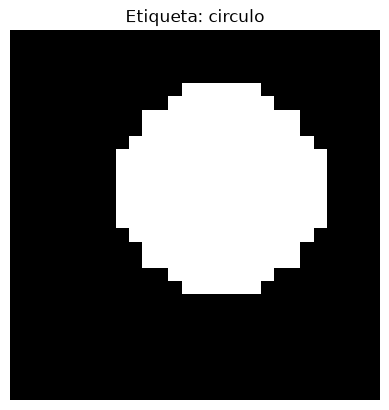

In [48]:
primera_ruta = CARPETA_IMAGENES / df.iloc[0]["archivo"]

imagen = Image.open(primera_ruta).convert("L")
matriz = np.array(imagen)

print("Archivo:", primera_ruta.name)
print("Forma de la imagen:", matriz.shape)
print("Tipo de dato:", matriz.dtype)
print("Valor mínimo:", matriz.min())
print("Valor máximo:", matriz.max())

plt.imshow(matriz, cmap="gray")
plt.title(f'Etiqueta: {df.iloc[0]["etiqueta"]}')
plt.axis("off")
plt.show()


## 4. Transformar todas las imágenes en datos numéricos

Fashion-MNIST utiliza imágenes de **28 × 28 píxeles**.

Cada imagen contiene:

\[
28 \times 28 = 784
\]

valores numéricos.

Para utilizar una red neuronal MLP convertiremos cada matriz de 28 × 28 en una fila de 784 características.


In [49]:
X_lista = []
y_lista = []

for _, fila in df.iterrows():
    ruta = CARPETA_IMAGENES / fila["archivo"]
    
    try:
        imagen = Image.open(ruta).convert("L")
        matriz = np.array(imagen)
        X_lista.append(matriz.reshape(-1))
        y_lista.append(fila["etiqueta"])
    except FileNotFoundError:
        # Si el archivo no existe, no hace nada y pasa al siguiente
        print(f"Archivo no encontrado, saltando: {fila['archivo']}")
        continue

X = np.array(X_lista)
y = np.array(y_lista)

### ¿Qué significa `X.shape = (60, 784)`?

- **60** corresponde a la cantidad de imágenes.
- **784** corresponde a los píxeles de cada imagen después de aplanarla.

La etiqueta correspondiente a cada fila de `X` se encuentra en la misma posición de `y`.


## 5. Normalizar los valores de los píxeles

Los píxeles originales poseen valores entre 0 y 255.

Dividiremos por 255 para transformarlos aproximadamente al rango 0–1.


In [50]:
print("Antes de normalizar:")
print("Mínimo:", X.min())
print("Máximo:", X.max())

X = X.astype("float32") / 255.0

print("\nDespués de normalizar:")
print("Mínimo:", X.min())
print("Máximo:", X.max())


Antes de normalizar:
Mínimo: 0
Máximo: 253

Después de normalizar:
Mínimo: 0.0
Máximo: 0.99215686


## 6. Separar entrenamiento y prueba

Reservaremos el 20 % de las imágenes para probar el modelo.

Usaremos `stratify=y` para intentar mantener la proporción de clases en ambos grupos.


In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (72, 784)
X_test : (18, 784)
y_train: (72,)
y_test : (18,)


## 7. Revisar la distribución de clases después de separar


In [52]:
print("Entrenamiento:")
display(pd.Series(y_train).value_counts().sort_index())

print("Prueba:")
display(pd.Series(y_test).value_counts().sort_index())


Entrenamiento:


circulo      24
cuadrado     24
triangulo    24
Name: count, dtype: int64

Prueba:


circulo      6
cuadrado     6
triangulo    6
Name: count, dtype: int64

## 8. Crear una red neuronal

Utilizaremos `MLPClassifier`, al igual que en la práctica anterior con Digits.

En este caso la capa de entrada recibe 784 características por imagen.

La capa oculta será una decisión de diseño del modelo.


In [53]:
modelo = MLPClassifier(
    hidden_layer_sizes=(32,),
    max_iter=1000,
    random_state=42
)

modelo


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(32,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


## 9. Entrenar

Durante `fit()` la red recibe:

- `X_train`: las imágenes convertidas a números;
- `y_train`: las etiquetas correspondientes.

A partir de ambos conjuntos ajusta internamente sus pesos.


In [54]:
modelo.fit(X_train, y_train)

print("Entrenamiento finalizado.")
print("Iteraciones realizadas:", modelo.n_iter_)


Entrenamiento finalizado.
Iteraciones realizadas: 120


## 10. Generar predicciones

Ahora entregaremos al modelo imágenes que no utilizó durante el entrenamiento.


In [55]:
predicciones = modelo.predict(X_test)

resultado = pd.DataFrame({
    "real": y_test,
    "predicha": predicciones
})

display(resultado)


,real,predicha
0,triangulo,triangulo
1,circulo,circulo
2,cuadrado,cuadrado
3,cuadrado,cuadrado
4,triangulo,triangulo
5,cuadrado,cuadrado
6,circulo,circulo
7,triangulo,triangulo
8,triangulo,triangulo
9,circulo,circulo


## 11. Calcular exactitud


In [56]:
exactitud = accuracy_score(y_test, predicciones)

print(f"Exactitud: {exactitud:.4f}")
print(f"Exactitud porcentual: {exactitud * 100:.2f}%")


Exactitud: 1.0000
Exactitud porcentual: 100.00%


## 12. Matriz de confusión

La matriz de confusión permite observar qué clases fueron reconocidas correctamente y cuáles se confundieron.


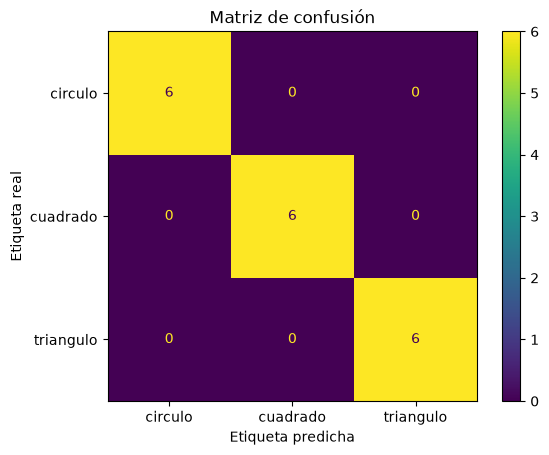

In [57]:
clases = sorted(df["etiqueta"].unique())

matriz_confusion = confusion_matrix(
    y_test,
    predicciones,
    labels=clases
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=clases
)

disp.plot()
plt.title("Matriz de confusión")
plt.xlabel("Etiqueta predicha")
plt.ylabel("Etiqueta real")
plt.show()


## 13. Mostrar imágenes de prueba con su resultado


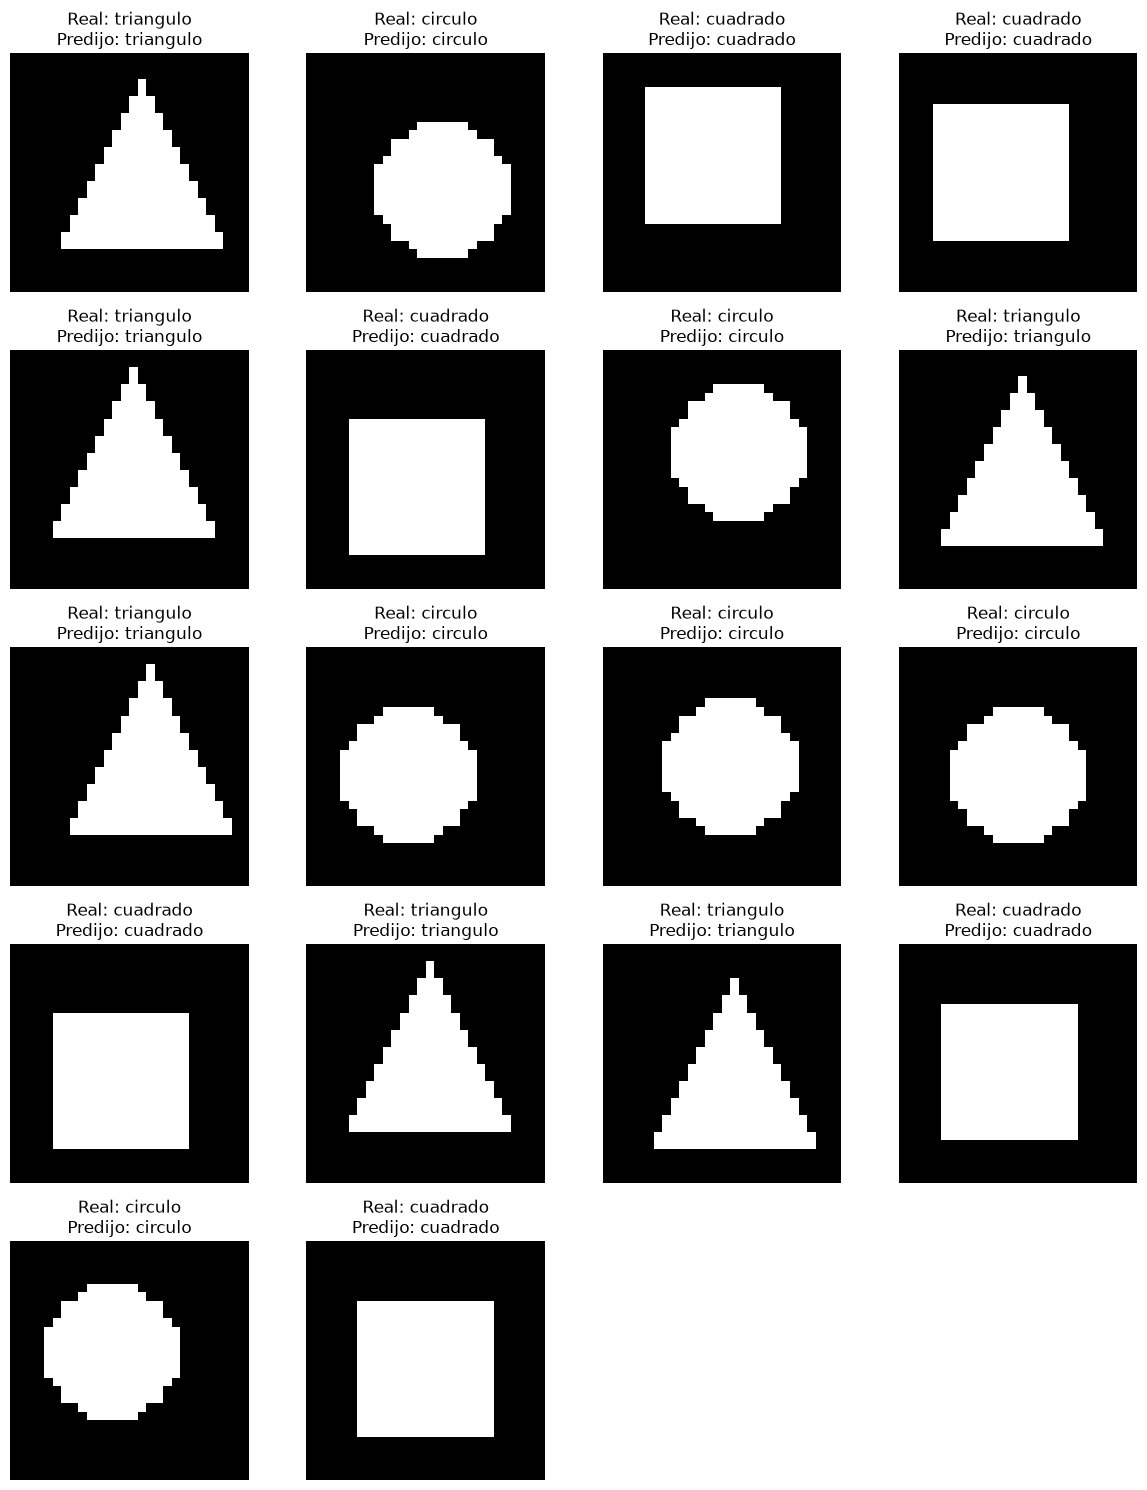

In [58]:
columnas = 4
filas = (len(X_test) + columnas - 1) // columnas

plt.figure(figsize=(12, 3 * filas))

for i in range(len(X_test)):
    plt.subplot(filas, columnas, i + 1)

    imagen = X_test[i].reshape(28, 28)

    plt.imshow(imagen, cmap="gray")
    plt.title(
        f"Real: {y_test[i]}\n"
        f"Predijo: {predicciones[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


## 14. Analizar únicamente los errores


In [59]:
indices_error = np.where(predicciones != y_test)[0]

print("Cantidad de errores:", len(indices_error))

if len(indices_error) == 0:
    print("El modelo clasificó correctamente todas las imágenes de prueba.")
else:
    columnas = 4
    filas = (len(indices_error) + columnas - 1) // columnas

    plt.figure(figsize=(12, 3 * filas))

    for posicion, indice in enumerate(indices_error, start=1):
        plt.subplot(filas, columnas, posicion)

        imagen = X_test[indice].reshape(28, 28)

        plt.imshow(imagen, cmap="gray")
        plt.title(
            f"Real: {y_test[indice]}\n"
            f"Predijo: {predicciones[indice]}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()


Cantidad de errores: 0
El modelo clasificó correctamente todas las imágenes de prueba.
